In [1]:
import pandas as pd
import os


os.chdir("../")

In [2]:
# data = pd.read_csv('data/telegram_spam_cleaned.csv')
use_tweet = True
if use_tweet:
    data = pd.read_csv('data/tweets.csv')
    data.rename(columns={"tweet_text": "text"}, inplace=True)
    data.drop(columns=['cyberbullying_type'], inplace=True)
data.drop_duplicates(subset=['text'], inplace=True)
display(data.columns, data.shape)
label = "label"
text = "text"

Index(['text'], dtype='str')

(46017, 1)

In [3]:
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme()
train, test = train_test_split(data, train_size=0.8)

In [4]:
len_symb = train[text].str.len()
len_word = train[text].apply(lambda x: len(x.split()))

36813
137.5633336049765 23.97794257463396


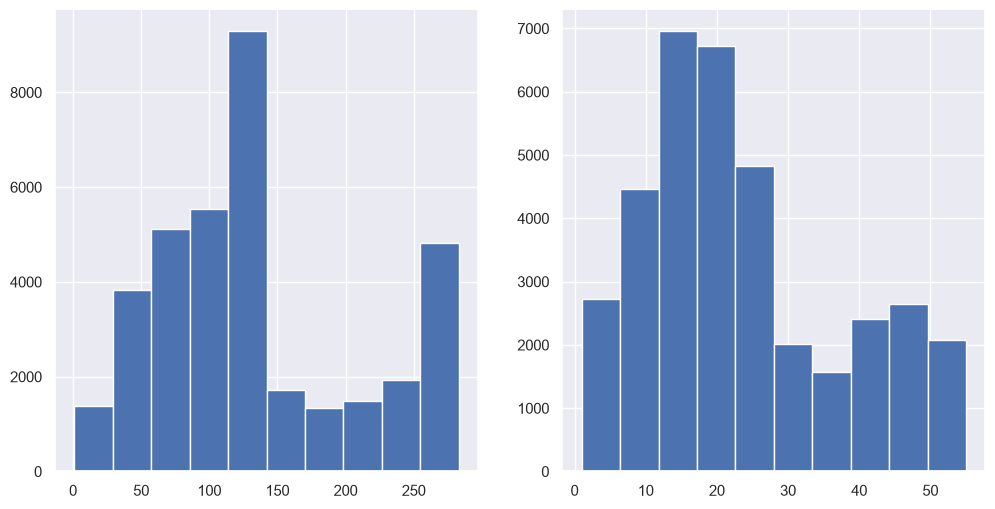

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 6))


ax[0].hist(len_symb[len_symb < len_symb.quantile(0.99)])
ax[1].hist(len_word[len_word < len_word.quantile(0.99)])
print(train.shape[0])
print(len_symb.mean(), len_word.mean())


50570


''

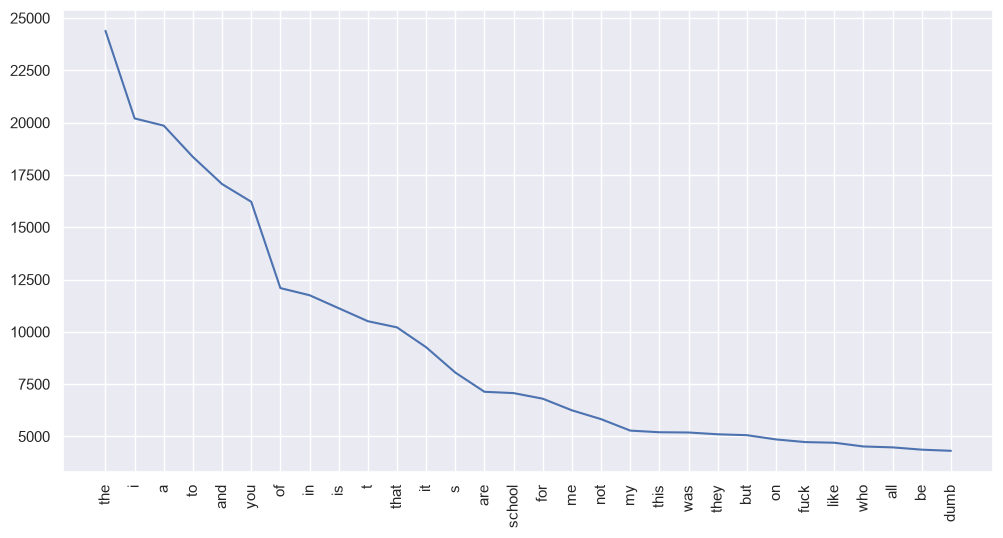

In [61]:
from collections import Counter
def unique_tokens(pd_ser):
    freq = Counter(pd_ser.str.lower().str.findall(r'[а-яa-z]+').explode())
    a = freq.most_common(30)
    x = [i[0] for i in a]
    y = [i[1] for i in a]
    plt.figure(figsize=(12,6))
    plt.plot(x, y)
    plt.xticks(rotation=90)
    print(len(freq))
    return freq
unique_tokens(train.text)
''

In [62]:
import unicodedata as ud
import pandas as pd
from collections import Counter
from itertools import chain

char_freq = Counter(chain.from_iterable(train['text'].dropna()))

df = pd.DataFrame(
    [(ch, f'U+{ord(ch):04X}', ud.category(ch), ud.name(ch, '?'), n)
     for ch, n in char_freq.items()],
    columns=['char', 'code', 'cat', 'name', 'count']
).sort_values('count', ascending=False)
display(df.head(20))
df.tail(20)


,char,code,cat,name,count
8,,U+0020,Zs,SPACE,846979
4,e,U+0065,Ll,LATIN SMALL LETTER E,397581
15,t,U+0074,Ll,LATIN SMALL LETTER T,307320
2,a,U+0061,Ll,LATIN SMALL LETTER A,302008
23,o,U+006F,Ll,LATIN SMALL LETTER O,292958
10,i,U+0069,Ll,LATIN SMALL LETTER I,269396
16,s,U+0073,Ll,LATIN SMALL LETTER S,244930
25,n,U+006E,Ll,LATIN SMALL LETTER N,235534
26,r,U+0072,Ll,LATIN SMALL LETTER R,200432
13,h,U+0068,Ll,LATIN SMALL LETTER H,187554


,char,code,cat,name,count
464,で,U+3067,Lo,HIRAGANA LETTER DE,1
469,す,U+3059,Lo,HIRAGANA LETTER SU,1
493,Ä,U+00C4,Lu,LATIN CAPITAL LETTER A WITH DIAERESIS,1
491,č,U+010D,Ll,LATIN SMALL LETTER C WITH CARON,1
488,ق,U+0642,Lo,ARABIC LETTER QAF,1
486,ら,U+3089,Lo,HIRAGANA LETTER RA,1
485,か,U+304B,Lo,HIRAGANA LETTER KA,1
484,こ,U+3053,Lo,HIRAGANA LETTER KO,1
483,て,U+3066,Lo,HIRAGANA LETTER TE,1
481,ば,U+3070,Lo,HIRAGANA LETTER BA,1


In [63]:
pd.set_option("display.max_colwidth", 255)

In [64]:
train[text].sample(20)

31039                                                                                                                                                                                                                            Dennis Rodman was a crazy ass bully ..
42128                   The black one up top on the right doesn’t even mean anything and you can tell that the black one on the bottom is photoshopped but for the other two they look real but it was like 4 years ago and he has apologized let shit from the past go
5528                                                                                                                                                                                                   Haven't started my paper so i'm not going to class. #goodstudent
46182                                                                                                                                    This is dumb little crusty cunt said "sand niggers are responsible for 

In [65]:
import emoji
import re
def replace_emoji(text, lang='en', sep=' '):
    if not isinstance(text, str):
        return text
    return emoji.replace_emoji(
        text,
        replace=lambda ch, data: f"{sep}{data[lang].strip(':').replace('_', ' ')}{sep}"
    ) 

def replace_url(text):
    p_tg = r'http[s]*://t.me/[a-zA-Z/]+'
    p = r'http[s]*://[a-zA-Z/]+'
    pn = r'[0-9]+'
    p_user = r'@[a-zA-Z_]+'
    text = re.sub(p_tg, '[URL_tg]', text)
    text = re.sub(p, '[URL]', text)
    text = re.sub(pn, '[NUM]', text)
    text = re.sub(p_user, '[USR]', text)
    return text

def replace_bn(text):
    p = r'[\n,.!\'"]'
    return re.sub(r'\s+', ' ', re.sub(p, ' ', text))

def pipeline(text):
    text = text.lower()
    de = replace_emoji(text)
    du = replace_url(de)
    dn = replace_bn(du)
    dn = '<s> ' + dn + ' </s>'
    return dn

In [66]:
train['text_prepared'] = train[text].apply(lambda x: pipeline(x))

In [67]:
train.text_prepared.sample(10)

13804                                                                                                                 <s> what a boring question [USR][NUM] am not sexist but can women league football ever get the kind of attention the men s league gets?????? </s>
24094                                                                                                                                                                                                                     <s> [USR] oh you meant wu - not publicly </s>
39020                                                                                                                                                                                               <s> you look like someone who would bully me in my high school </s>
26863                                                                                                                                                                      <s> rt [USR]: [USR][NUM]_[NUM] [USR] 

### lem & stem

In [68]:
import nltk

nltk.download('stopwords')
nltk.download('punkt', quiet=True)
nltk.download('wordnet', quiet=True)

from nltk.stem import PorterStemmer, SnowballStemmer

import pymorphy3
from nltk.stem import WordNetLemmatizer

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/eugene/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [69]:
st = SnowballStemmer('russian')
pt = PorterStemmer()
morph = pymorphy3.MorphAnalyzer()
lemmatizer_en = WordNetLemmatizer()

def stem(text):
    return ' '.join([st.stem(i) if len(re.findall('[а-я]', i.lower())) > 0 else pt.stem(i) for i in text.split()])
def lem(text):
    return ' '.join([
        morph.parse(i)[0].normal_form if len(re.findall('[а-я]', i.lower())) > 0 else lemmatizer_en.lemmatize(i) for i in text.split()
    ])

In [70]:
display(stem('белый вид дохода fatting lazy cat sat on a mate нужно [NUM]-[NUM] часа в день принимаем как с опытом так и без возраст от [NUM][NUM] лет пишите + в л'))
lem(('белый вид дохода нужно fatting lazy cat sat on a mate часа в день принимаем как с опытом так и без возраст от [NUM][NUM] лет пишите + в л'))

'бел вид доход fat lazi cat sat on a mate нужн [num]-[num] час в ден принима как с опыт так и без возраст от [num][num] лет пиш + в л'

'белый вид доход нужно fatting lazy cat sat on a mate час в день принимать как с опыт так и без возраст от [NUM][NUM] год писать + в л'

33159


''

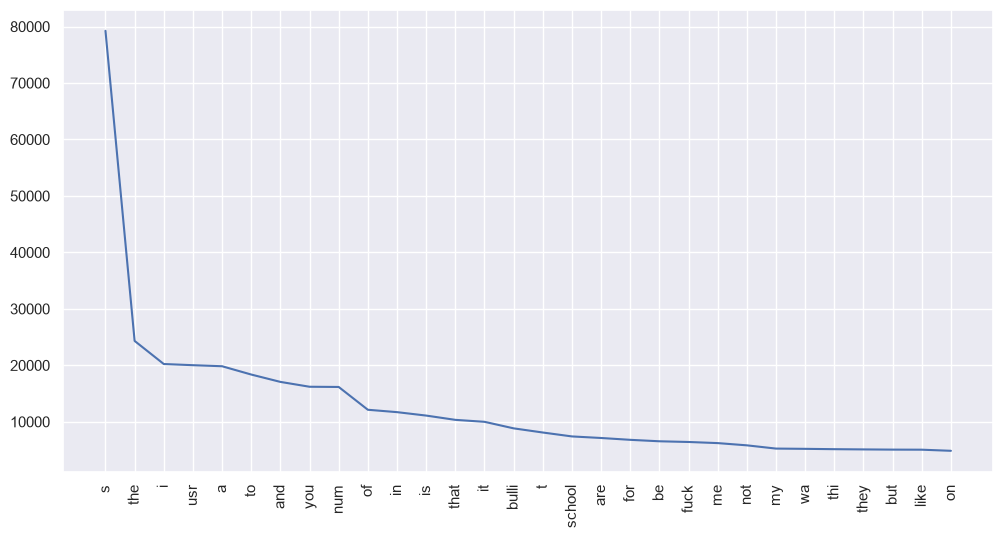

In [71]:
unique_tokens(train.text_prepared.apply(lambda x: stem(x)))
''

38047


''

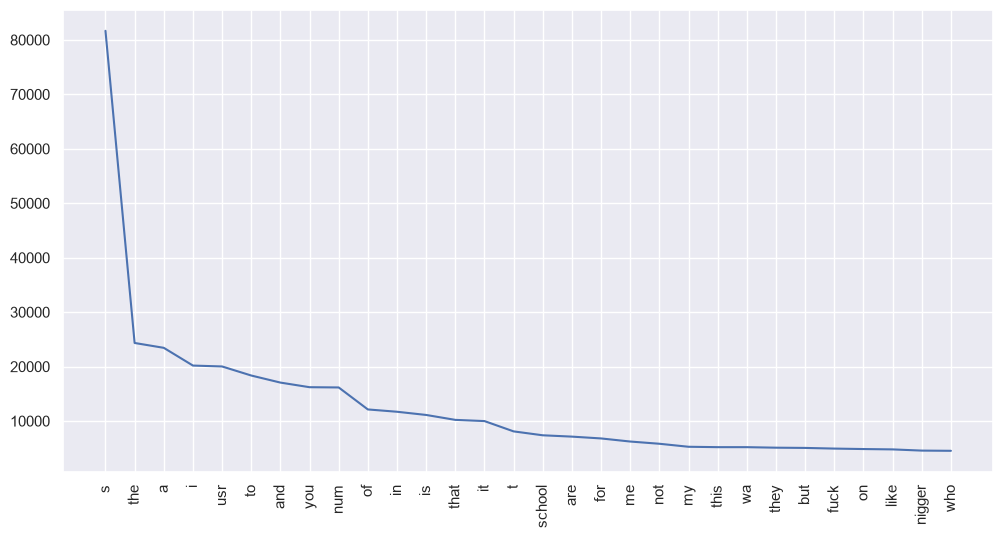

In [72]:
unique_tokens(train.text_prepared.apply(lambda x: lem(x)))
''

### Vocab


In [73]:
train.text_prepared = train[text].apply(lambda x: pipeline(x))
train.text_prepared = train.text_prepared.apply(lambda x: stem(x))

n_unique = 3

vocabulary = Counter(train.text_prepared.str.split().explode())
vocabulary = set([i[0] for i in vocabulary.items() if i[1] > n_unique]) | set(['[UNK]'])
len(vocabulary)

8447

In [74]:
txt = train[text].apply(lambda x: pipeline(x)).sample(1).values[0]
display(stem(txt))
display(lem(txt))

stem(txt) == lem(txt)

'<s> #mkr the team all gave crap score asid from the melbourn girl ridicul kat and andr shouldn t stay in the competit </s>'

'<s> #mkr the team all gave crap score aside from the melbourne girl ridiculous kat and andre shouldn t stay in the competition </s>'

False

In [75]:
# vocabulary

In [76]:
def replace_unk(text, vocabulary=vocabulary):
    return " ".join([i if i in vocabulary else '[UNK]' for i in text.split()])

In [77]:
train.text_prepared = train.text_prepared.apply(lambda x: replace_unk(x))
vocabulary_counts = Counter(train.text_prepared.str.split().explode())

### N-gramm test

In [78]:
# fix
# vocabulary_counts['[UNK]'] = 1
depth = 3
stats = {}
for row in train.text_prepared:
    row = row.split()
    for i in range(0, len(row) - depth):
        c = 0
        c_stats = stats
        for c in range(depth - 1):
            word = row[i + c]
            if word == '[UNK]':
                break
            if c < depth - 2:
                c_stats.setdefault(word, {})
                c_stats = c_stats[word]
            
            elif c == depth - 2:
                c_stats.setdefault(word, {})
                fin_word = row[i + c + 1]
                if fin_word == '[UNK]':
                    break
                c_stats[word].setdefault(fin_word, 0)
                c_stats[word][fin_word] += 1
    

# for key in stats.keys():
#     for k2 in stats[key]:
#         stats[key][k2] /= (vocabulary_counts[key] + 1)

In [79]:
# step(['<s>', 'весь',], stats)

In [80]:
def step(prev: list, stats):
    assert len(prev) == depth - 1, 'wrong len list prev'
    for i in prev:
        if not i in stats:
            return '[UNK]'
        stats = stats[i]
        # print(stats, i)
    ans = sorted(stats.items(), key=lambda x:x[1], reverse=True)
    if len(ans) == 0:
        return '[UNK]'
    return ans[0][0]

def inference(text, stats):
    ans = text[::]
    tokens = text.split()[-depth + 1:]
    i = 0
    next_token = ''
    while next_token != '</s>':
        # print(tokens)
        next_token = step(tokens, stats)
        ans += ' ' + next_token
        tokens = tokens[1:] + [next_token]
        i += 1
        if i == 50:
            print('limit')
            break
    ans += ' </s>'
    return ans
        
    

In [81]:
stats['sheesh']

{'[usr]': {'hey': 1},
 'river': {'is': 1},
 'and': {'don’t': 1},
 'the': {'girl': 1}}

In [83]:
print(inference('<s> hello you', stats))
print(inference('<s> [usr] i', stats))
print(inference('<s> sheesh', stats))
print(inference('<s> games', stats))
print(inference('<s> time', stats))

limit
<s> hello you absolut idiot i’m muslim and christian are bad and when i wa bulli in high school bulli who call me a nigger you dumb nigger fuck you dumb nigger fuck you dumb nigger fuck you dumb nigger fuck you dumb nigger fuck you dumb nigger fuck you dumb nigger fuck </s>
limit
<s> [usr] i m not sexist but i m not sexist but i m not sexist but i m not sexist but i m not sexist but i m not sexist but i m not sexist but i m not sexist but i m not sexist but i m not sexist but i </s>
limit
<s> sheesh river is such a bulli in high school bulli who call me a nigger you dumb nigger fuck you dumb nigger fuck you dumb nigger fuck you dumb nigger fuck you dumb nigger fuck you dumb nigger fuck you dumb nigger fuck you dumb nigger fuck you dumb nigger fuck </s>
limit
<s> games [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK]

## N-gramm norm

In [84]:
import collections
bigrams = []
unigrams = []
for row in train.text_prepared:
    tokens = row.split()
    bigrams.extend([(tokens[i], tokens[i + 1]) for i in range(len(tokens) - 1) if not any([tokens[i] == "[UNK]", tokens[i + 1] == "[UNK]"])])
    unigrams.extend([(tokens[i],)for i in range(len(tokens) - 1) if not any([tokens[i] == "[UNK]"])])
bigram_counts = collections.Counter(bigrams)
unigram_counts = collections.Counter(unigrams)

In [85]:
bigram_counts.most_common(5)

[(('<s>', '[usr]'), 6528),
 (('high', 'school'), 3539),
 (('[usr]', '[usr]'), 3177),
 (('<s>', 'i'), 2809),
 (('<s>', 'rt'), 2446)]

In [86]:
from typing import Dict
depth = 2

    
def inference(source_text, score_func):
    ans = text[::]
    tokens = text.split()[-depth + 1:]
    i = 0
    next_token = ''
    while next_token != '</s>':
        # print(tokens)
        next_token = score_func(*tokens, **kwargs)
        ans += ' ' + next_token
        tokens = tokens[1:] + [next_token]
        i += 1
        if i == 50:
            print('limit')
            break
    ans += ' </s>'
    return ans

In [87]:
v_size = len(vocabulary)
def laplasse_add(*words, **kwargs):
    up = bigram_counts.get((words), 0)
    down = unigram_counts.get((words[:-1]), 0)
    return (up + kwargs['alpha']) / (down + v_size * kwargs['alpha'])

In [88]:
import numpy as np
def perplexity(text: str, score_func):
    tokens = text.split()
    N = len(tokens)
    array = np.array([np.log2(score_func(tokens[i], tokens[i + 1], **kwargs)) for i in range(N - 1)])
    # print(array)
    sm = array.sum()
    return 2 ** (-(1/N) * sm)


def perplexity_on_df(df, score_func, text="text_prepared"):
    return df[text].apply(lambda x: perplexity(x, score_func))

In [89]:
kwargs = {'alpha': 0.1}
perplexity_on_df(train, laplasse_add).mean()

np.float64(314.5360969384111)

### test on test

In [90]:
test['text_prepared'] = test[text].apply(lambda x: pipeline(x))
test['text_prepared'] = test.text_prepared.apply(lambda x: stem(x))
kwargs = {'alpha': 0.1}
perplexity_on_df(test, laplasse_add).mean()

np.float64(573.3369006327068)

In [91]:
kwargs = {'alpha': 0}
perplexity_on_df(test, laplasse_add).mean()

/var/folders/8k/pf6tyzbs6fb8nk60l1m38lym0000gp/T/ipykernel_95265/2813345464.py:5: RuntimeWarning: divide by zero encountered in log2
  array = np.array([np.log2(score_func(tokens[i], tokens[i + 1], **kwargs)) for i in range(N - 1)])


ZeroDivisionError: division by zero

In [ ]:
bigram_counts.get(('<s>', 'hi'))

In [ ]:
bigram_counts.most_common(5)

In [ ]:
laplasse_add(*'<s> [USR]'.split(), **kwargs)

In [ ]:
laplasse_add(*'<s> [USR]'.split(), alpha=0)